# 10.5 · Solutions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/10-deployment-mlops/05-mlflow/solutions.ipynb)

In [1]:
# --- course files: found locally, downloaded on Colab -------------------------
import sys, urllib.request
from pathlib import Path
REPO_RAW = "https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/"

def repo_file(rel):
    """Return a local path to a file in this repo, downloading it if needed."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        if (parent / rel).exists():
            return parent / rel
    dest = Path("course_files") / rel
    dest.parent.mkdir(parents=True, exist_ok=True)
    if not dest.exists():
        urllib.request.urlretrieve(REPO_RAW + rel, dest)
    return dest

import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
repo_file("data/download.py")                                  # churn_model finds the data through it
sys.path.insert(0, str(repo_file("lib/churn_model.py").parent))
import churn_model as cm

bundle = cm.load_bundle()          # trains and saves models/churn_bundle.joblib the first time
ROOT = cm.repo_root()
print(f"Model trained {bundle['trained']}, test AUC {bundle['metrics']['test_auc']}, "
      f"threshold {bundle['threshold']}")

Model trained 2026-10-28, test AUC 0.741, threshold 0.07


In [2]:
import os, logging
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
import mlflow, mlflow.sklearn
logging.getLogger("mlflow").setLevel(logging.ERROR)     # hide MLflow's informational notices

(ROOT / "mlruns").mkdir(exist_ok=True)
mlflow.set_tracking_uri(f"sqlite:///{(ROOT / 'mlruns' / 'mlflow.db').as_posix()}")
EXPERIMENT = "shopwave-churn"
if mlflow.get_experiment_by_name(EXPERIMENT) is None:
    mlflow.create_experiment(EXPERIMENT, artifact_location=(ROOT / "mlruns" / "artifacts").as_uri())
mlflow.set_experiment(EXPERIMENT)
print("Tracking runs in mlruns/mlflow.db at the course root")

Tracking runs in mlruns/mlflow.db at the course root


In [3]:
from sklearn.model_selection import train_test_split
cust = cm.build_customer_table(cm.load_sales())
X_train, X_test, y_train, y_test = train_test_split(
    cust[cm.FEATURES], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, train {len(X_train):,} / test {len(X_test):,}")

3,317 customers, train 2,487 / test 830


In [4]:
from mlflow import MlflowClient
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score
client = MlflowClient()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## Exercise 1

In [5]:
from sklearn.neighbors import KNeighborsClassifier
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=51))
with mlflow.start_run(run_name="knn_51"):
    s = cross_val_score(knn, X_train, y_train, cv=cv, scoring="roc_auc")
    knn.fit(X_train, y_train)
    p = knn.predict_proba(X_test)[:, 1]
    mlflow.log_params({"model": "knn_51", "n_neighbors": 51, "split_seed": 42})
    mlflow.log_metrics({"cv_auc": s.mean(), "cv_auc_std": s.std(), "test_auc": roc_auc_score(y_test, p)})
runs = mlflow.search_runs(experiment_names=[EXPERIMENT], order_by=["metrics.cv_auc DESC"])
print(runs[["tags.mlflow.runName", "metrics.cv_auc", "metrics.test_auc"]].round(3).to_string(index=False))

tags.mlflow.runName  metrics.cv_auc  metrics.test_auc
logistic_regression           0.740             0.741
      random_forest           0.736             0.731
             knn_51           0.732             0.734
       tree_depth_3           0.731             0.724
       tree_depth_8           0.683             0.649


KNN (CV 0.732) lands inside the tied group, between the random forest and the depth-3 tree, as in 05.10. (This run skips `log_model`: you can log metrics without the model when you only want the comparison.)

## Exercise 2

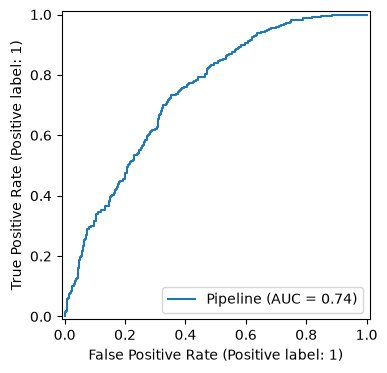

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay
with mlflow.start_run(run_name="logreg_with_roc"):
    model = bundle["pipeline"]
    fig, ax = plt.subplots(figsize=(4, 4))
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=ax)
    mlflow.log_figure(fig, "roc.png")
    mlflow.log_metric("test_auc", roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]))
plt.show()

## Exercise 3

In [7]:
rf_run = mlflow.search_runs(experiment_names=[EXPERIMENT],
                            filter_string="tags.mlflow.runName = 'random_forest'", output_format="list")[0]
rf_uri = mlflow.search_logged_models(experiment_ids=[rf_run.info.experiment_id],
                                     filter_string=f"source_run_id = '{rf_run.info.run_id}'",
                                     output_format="list")[0].model_uri
import contextlib, io
with contextlib.redirect_stderr(io.StringIO()):
    version = mlflow.register_model(rf_uri, "shopwave-churn")
client.set_registered_model_alias("shopwave-churn", "challenger", version.version)

def compare_aliases():
    for alias in ["champion", "challenger"]:
        m = mlflow.sklearn.load_model(f"models:/shopwave-churn@{alias}")
        print(f"@{alias:10s} test AUC {roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]):.3f}")
compare_aliases()

@champion   test AUC 0.741
@challenger test AUC 0.731


The challenger scores lower on this test set, and 10.5's leaderboard says the two are tied on CV. Before promoting a challenger you would want: a CV advantage larger than the noise, a better result on **new** customers (the latest month, once labels arrive, 10.6), no worse fairness (10.7), and an acceptable cost and latency. Then moving `@champion` is one call, and moving it back is one call too.